# Lab 01 · 과적합, 교차검증, 데이터 누수, 평가 지표

**이 실습이 다루는 자료** ([필독 목록](../READING_LIST.md) · [실습 가이드](../PRACTICE.md))

| 절 | 직접 확인할 것 | 관련 자료 |
|---|---|---|
| 1 | 모델이 복잡해지면 train 오차와 test 오차가 갈라지는 모습 | Domingos (2012) *A Few Useful Things* |
| 2 | 한 번의 분할로 잰 성능은 얼마나 흔들리는가 | [ML 기초](../../00_Foundations/04_ml-basics.md) |
| 3–4 | 데이터 누수 두 가지: 분할 전 전처리, 그룹 누수 | Kapoor & Narayanan (2022) *Leakage and the Reproducibility Crisis* |
| 5 | 불균형 데이터에서 accuracy·ROC-AUC·PR-AUC가 말해 주는 것 | SMOTE (2002), *To SMOTE, or not to SMOTE?* (2022) |

**진행 방법**: `✍️ 예측` 질문에 먼저 답하고 실행하세요. · **소요 시간**: 60~90분 · **패키지**: numpy, pandas, matplotlib, scikit-learn

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.model_selection import cross_val_score, train_test_split, KFold, GroupKFold, StratifiedKFold
from sklearn.metrics import mean_squared_error, roc_auc_score, average_precision_score, roc_curve, precision_recall_curve
rng = np.random.default_rng(0)
plt.rcParams.update({"figure.figsize": (7, 3.5), "figure.dpi": 80, "axes.grid": True, "grid.alpha": 0.3})

## 1. 과적합: 연습문제 점수와 시험 점수가 갈라지는 순간

참 함수는 $y=\sin(2\pi x)$ 이고 관측에는 잡음이 섞여 있습니다. 학습 데이터는 30개뿐입니다. 다항식 차수를 1부터 15까지 올려 봅니다.

✍️ **예측**: 차수를 올릴수록 (a) train 오차와 (b) test 오차는 각각 어떻게 움직일까요?

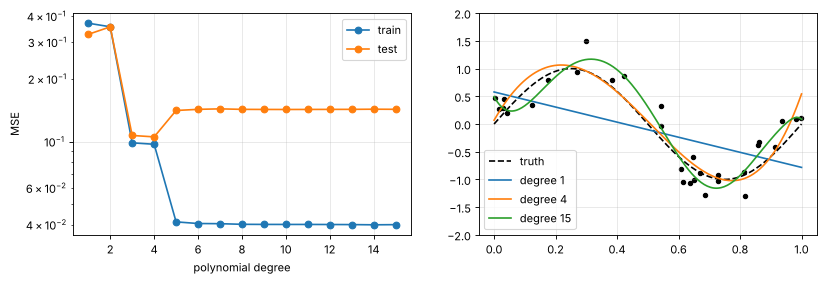

test MSE가 가장 낮은 차수: 4 | 잡음의 분산(도달 가능한 하한) = 0.09


In [2]:
def make_data(n):
    x = rng.uniform(0, 1, n)
    return x[:, None], np.sin(2 * np.pi * x) + rng.normal(0, 0.3, n)

X_tr, y_tr = make_data(30)
X_te, y_te = make_data(2000)
degrees = range(1, 16)
train_err, test_err = [], []
for d in degrees:
    model = make_pipeline(PolynomialFeatures(d), StandardScaler(), LinearRegression()).fit(X_tr, y_tr)
    train_err.append(mean_squared_error(y_tr, model.predict(X_tr)))
    test_err.append(mean_squared_error(y_te, model.predict(X_te)))

fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
axes[0].plot(degrees, train_err, "o-", label="train"); axes[0].plot(degrees, test_err, "o-", label="test")
axes[0].set_yscale("log"); axes[0].set_xlabel("polynomial degree"); axes[0].set_ylabel("MSE"); axes[0].legend()
xs = np.linspace(0, 1, 200)[:, None]
axes[1].scatter(X_tr, y_tr, c="k", s=15); axes[1].plot(xs, np.sin(2 * np.pi * xs), "k--", label="truth")
for d in [1, 4, 15]:
    m = make_pipeline(PolynomialFeatures(d), StandardScaler(), LinearRegression()).fit(X_tr, y_tr)
    axes[1].plot(xs, m.predict(xs), label=f"degree {d}")
axes[1].set_ylim(-2, 2); axes[1].legend(); plt.show()
print("test MSE가 가장 낮은 차수:", degrees[int(np.argmin(test_err))], "| 잡음의 분산(도달 가능한 하한) = 0.09")

- train 오차는 차수를 올릴수록 **계속** 내려갑니다. test 오차는 내려가다가 다시 올라갑니다.
- 차수 1은 **과소적합**(편향이 큼), 차수 15는 **과적합**(분산이 큼)입니다.
- test MSE는 아무리 좋아도 잡음의 분산(0.3² = 0.09) 아래로는 내려갈 수 없습니다. 논문에서 "성능 상한"을 따질 때 떠올릴 개념입니다.

## 2. 한 번의 분할은 얼마나 믿을 만한가

같은 데이터·같은 모델인데 **분할 시드만** 바꿔서 성능을 30번 잽니다.

✍️ **예측**: hold-out(8:2 한 번)과 5-fold 교차검증 중 어느 쪽 값이 더 덜 흔들릴까요?

In [3]:
from sklearn.datasets import make_classification
X, y = make_classification(n_samples=300, n_features=20, n_informative=5, random_state=0)
clf = LogisticRegression(max_iter=1000)
holdout, cv5 = [], []
for seed in range(30):
    Xa, Xb, ya, yb = train_test_split(X, y, test_size=0.2, random_state=seed)
    holdout.append(clf.fit(Xa, ya).score(Xb, yb))
    cv5.append(cross_val_score(clf, X, y, cv=KFold(5, shuffle=True, random_state=seed)).mean())
print(f"hold-out   : 평균 {np.mean(holdout):.3f}, 표준편차 {np.std(holdout):.3f}, 범위 {min(holdout):.3f} ~ {max(holdout):.3f}")
print(f"5-fold CV  : 평균 {np.mean(cv5):.3f}, 표준편차 {np.std(cv5):.3f}, 범위 {min(cv5):.3f} ~ {max(cv5):.3f}")

hold-out   : 평균 0.801, 표준편차 0.044, 범위 0.700 ~ 0.867
5-fold CV  : 평균 0.812, 표준편차 0.011, 범위 0.793 ~ 0.840


분할 하나로 잰 정확도는 시드에 따라 몇 %p씩 달라집니다. 논문 표에서 **0.5%p 개선**을 주장할 때 "시드를 몇 번 돌렸는가", "표준편차는 얼마인가"를 확인해야 하는 이유입니다.

## 3. 데이터 누수 ①: 분할하기 전에 한 전처리

**완전한 잡음** 데이터를 만듭니다. 특성 5,000개, 표본 100개, 라벨은 동전 던지기입니다. 어떤 모델도 50%를 넘을 수 없어야 합니다.

✍️ **예측**: 전체 데이터에서 "라벨과 가장 관련 있어 보이는 특성 20개"를 먼저 고른 다음 교차검증을 하면 정확도는 얼마가 나올까요?

In [4]:
from sklearn.feature_selection import SelectKBest, f_classif
Xn = rng.normal(size=(100, 5000))
yn = rng.integers(0, 2, 100)

# (잘못된 방법) 전체 데이터로 특성 선택 → 그다음 교차검증
X_selected = SelectKBest(f_classif, k=20).fit_transform(Xn, yn)
wrong = cross_val_score(LogisticRegression(max_iter=1000), X_selected, yn, cv=5).mean()

# (올바른 방법) 특성 선택을 파이프라인 안에 넣어 fold마다 train 부분만으로 수행
pipe = make_pipeline(SelectKBest(f_classif, k=20), LogisticRegression(max_iter=1000))
right = cross_val_score(pipe, Xn, yn, cv=5).mean()
print(f"잘못된 방법의 CV 정확도 = {wrong:.2f}   올바른 방법의 CV 정확도 = {right:.2f}   (참값은 0.50)")

잘못된 방법의 CV 정확도 = 0.94   올바른 방법의 CV 정확도 = 0.57   (참값은 0.50)


라벨이 **무작위**인데도 잘못된 절차는 매우 높은 정확도를 보고합니다. (올바른 방법의 값이 정확히 0.50이 아닌 것은 표본이 100개뿐이라 ±0.05 정도 흔들리기 때문입니다.) 특성 선택 단계에서 이미 검증용 데이터의 라벨을 "봤기" 때문입니다.  
스케일링, 결측 대체, 타깃 인코딩, 오버샘플링(SMOTE) 모두 같은 원리로 누수를 일으킬 수 있습니다. **`Pipeline` 안에 넣는 것**이 가장 간단한 방지책입니다.

## 4. 데이터 누수 ②: 같은 사람의 데이터가 train과 test에 모두 있을 때

사용자 200명이 각자 10행씩 가진 데이터입니다. 라벨은 사용자 단위로 정해지고(무작위), 특성에는 라벨과 **무관한** "사용자 고유의 흔적"만 들어 있습니다. 새로운 사용자에 대해서는 예측이 불가능한 데이터입니다.

✍️ **예측**: 행 단위로 무작위 분할(KFold)하면 정확도가 얼마나 나올까요? 사용자 단위로 분할(GroupKFold)하면?

In [5]:
from sklearn.neighbors import KNeighborsClassifier
n_users, rows = 200, 10
user = np.repeat(np.arange(n_users), rows)
fingerprint = rng.normal(size=(n_users, 10))                    # 사용자 고유의 흔적 (라벨과 무관)
Xg = fingerprint[user] + rng.normal(0, 0.3, size=(n_users * rows, 10))
yg = rng.integers(0, 2, n_users)[user]                            # 사용자별 라벨 (무작위)

knn = KNeighborsClassifier(n_neighbors=1)
acc_random = cross_val_score(knn, Xg, yg, cv=KFold(5, shuffle=True, random_state=0)).mean()
acc_group = cross_val_score(knn, Xg, yg, cv=GroupKFold(5), groups=user).mean()
print(f"행 단위 무작위 분할 정확도 = {acc_random:.2f}   사용자 단위 분할 정확도 = {acc_group:.2f}")

행 단위 무작위 분할 정확도 = 0.99   사용자 단위 분할 정확도 = 0.50


무작위 분할에서는 모델이 "이 행은 아까 본 그 사용자다"를 알아보고 그 사용자의 라벨을 그대로 답합니다. **배포 후에 만날 상황(새 사용자, 미래 시점)과 같은 방식으로 분할**해야 합니다.
- 같은 사용자·환자·문서가 여러 행 → `GroupKFold`
- 시간 순서가 있는 데이터 → 과거로 학습, 미래로 평가 (`TimeSeriesSplit`)

## 5. 불균형 데이터의 평가 지표

양성이 1%뿐인 데이터(예: 사기 거래)입니다.

✍️ **예측**: "전부 음성"이라고 답하는 모델의 accuracy는? 그 모델의 ROC-AUC와 PR-AUC는?

양성 비율 = 0.010
'전부 음성' 모델   accuracy = 0.990
로지스틱 회귀      accuracy = 0.990   ROC-AUC = 0.920   PR-AUC = 0.271
양성의 절반을 잡는 지점(recall 0.5)의 precision = 0.19


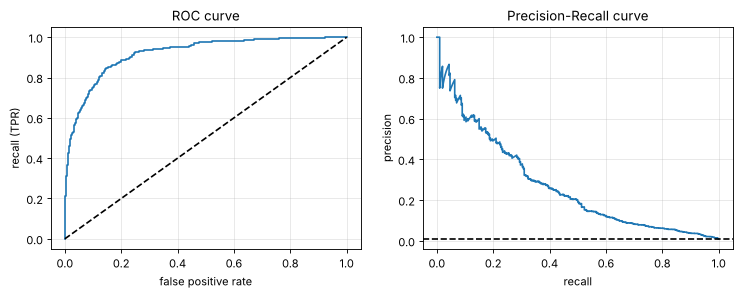

In [6]:
from sklearn.dummy import DummyClassifier
n = 60000
yi = (rng.random(n) < 0.01).astype(int)                 # 양성 1%
Xi = rng.normal(size=(n, 5)); Xi[yi == 1, :2] += 1.4    # 양성은 두 특성의 평균이 1.4만큼 높다 (분포는 많이 겹친다)
Xa, Xb, ya, yb = train_test_split(Xi, yi, test_size=0.5, stratify=yi, random_state=0)
dummy = DummyClassifier(strategy="most_frequent").fit(Xa, ya)
model = LogisticRegression(max_iter=2000).fit(Xa, ya)
proba = model.predict_proba(Xb)[:, 1]
fpr, tpr, _ = roc_curve(yb, proba); prec, rec, _ = precision_recall_curve(yb, proba)
i50 = int(np.argmin(np.abs(rec - 0.5)))
print(f"양성 비율 = {yb.mean():.3f}")
print(f"'전부 음성' 모델   accuracy = {dummy.score(Xb, yb):.3f}")
print(f"로지스틱 회귀      accuracy = {model.score(Xb, yb):.3f}   ROC-AUC = {roc_auc_score(yb, proba):.3f}   PR-AUC = {average_precision_score(yb, proba):.3f}")
print(f"양성의 절반을 잡는 지점(recall 0.5)의 precision = {prec[i50]:.2f}")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
axes[0].plot(fpr, tpr); axes[0].plot([0, 1], [0, 1], "k--"); axes[0].set_xlabel("false positive rate"); axes[0].set_ylabel("recall (TPR)"); axes[0].set_title("ROC curve")
axes[1].plot(rec, prec); axes[1].axhline(yb.mean(), color="k", ls="--"); axes[1].set_xlabel("recall"); axes[1].set_ylabel("precision"); axes[1].set_title("Precision-Recall curve")
plt.show()

- accuracy는 "전부 음성" 모델과 거의 차이가 없어 **아무것도 말해 주지 않습니다**.
- ROC-AUC는 0.9 안팎으로 좋아 보입니다. 그런데 양성의 절반을 잡는 지점에서 precision은 0.2 안팎입니다. **경보 5건 중 4건이 오탐**이라는 뜻입니다. 음성이 압도적으로 많으면 FPR이 2%만 되어도 오탐의 절대 수가 양성보다 많아지기 때문입니다.
- PR-AUC의 기준선은 0.5가 아니라 **양성 비율**(여기서는 약 0.01)입니다. 불균형이 심할수록 ROC-AUC와 PR-AUC를 함께 봐야 합니다.
- 실제로는 "precision이 최소 얼마여야 하는가" 같은 **업무 조건에서 임계값을 정하고** 그 지점의 precision/recall을 보고합니다.

---
## 직접 해보기

1. **(타깃 인코딩 누수)** 아래 데이터는 범주형 변수 `shop`(2,000종)과 무작위 라벨로 이루어져 있습니다. "가게별 양성 비율"을 특성으로 쓰는 타깃 인코딩을 (a) 전체 데이터로 계산한 뒤 교차검증하는 방법과 (b) fold마다 train 부분으로만 계산하는 방법으로 각각 구현하고 ROC-AUC를 비교하세요. 참값은 0.5입니다.
2. **(임계값 정하기)** 5절의 모델에서 precision이 0.5 이상이 되는 가장 낮은 임계값을 찾고, 그때의 recall을 구하세요.
3. **(생각해 보기)** 3절의 잘못된 방법을 쓴 논문을 읽는다면, 본문의 어느 문장에서 그 사실을 알아챌 수 있을까요?

In [7]:
shop = rng.integers(0, 2000, 10000)
y_shop = rng.binomial(1, 0.3, 10000)
# TODO 1: (a) 누수가 있는 타깃 인코딩  (b) fold 안에서만 계산하는 타깃 인코딩

# TODO 2: precision >= 0.5 가 되는 가장 낮은 임계값과 그때의 recall

---
## 정답 예시 (먼저 풀어 본 뒤 확인)

In [8]:
# 1. 타깃 인코딩
df = pd.DataFrame({"shop": shop, "y": y_shop})

# (a) 누수: 전체 데이터(자기 자신의 라벨 포함)로 가게별 평균을 계산
enc_all = df.groupby("shop")["y"].transform("mean").to_numpy()[:, None]
auc_leaky = cross_val_score(LogisticRegression(), enc_all, df["y"], cv=5, scoring="roc_auc").mean()

# (b) 올바른 방법: 각 fold에서 train 부분으로만 평균을 계산해 valid 부분에 적용
aucs = []
for tr_idx, va_idx in StratifiedKFold(5, shuffle=True, random_state=0).split(df, df["y"]):
    tr, va = df.iloc[tr_idx], df.iloc[va_idx]
    means = tr.groupby("shop")["y"].mean()
    prior = tr["y"].mean()
    f_tr = tr["shop"].map(means).to_numpy()[:, None]                 # (엄밀히는 train 쪽도 out-of-fold로 만드는 것이 더 좋다)
    f_va = va["shop"].map(means).fillna(prior).to_numpy()[:, None]   # train에 없던 가게는 전체 평균으로
    m = LogisticRegression().fit(f_tr, tr["y"])
    aucs.append(roc_auc_score(va["y"], m.predict_proba(f_va)[:, 1]))
print(f"(a) 누수 있는 방법 AUC = {auc_leaky:.3f}    (b) fold 안에서 계산 AUC = {np.mean(aucs):.3f}    (참값 0.5)")

(a) 누수 있는 방법 AUC = 0.773    (b) fold 안에서 계산 AUC = 0.501    (참값 0.5)


In [9]:
# 2. precision >= 0.5 인 가장 낮은 임계값
prec, rec, thr = precision_recall_curve(yb, proba)
ok = np.nonzero(prec[:-1] >= 0.5)[0]
i = ok[0]                                   # thr는 오름차순이므로 처음 만족하는 지점이 가장 낮은 임계값
print(f"임계값 = {thr[i]:.3f},  precision = {prec[i]:.2f},  recall = {rec[i]:.2f}")

임계값 = 0.253,  precision = 0.50,  recall = 0.21


**3번 생각해 보기**: Methods에 "we first selected the top-k features (or normalized / oversampled the dataset) and then performed cross-validation" 처럼 **전처리가 분할보다 먼저** 나오는 서술, 또는 분할 방식(무작위/그룹/시간)이 아예 적혀 있지 않은 경우가 신호입니다. Kapoor & Narayanan (2022)의 누수 분류표를 점검표로 쓰세요.

---
## 논문으로 돌아가기

| 방금 한 것 | 논문에서 확인할 곳 |
|---|---|
| 1절 | Domingos (2012)의 "Overfitting has many faces" 절 — 편향·분산 그림(다트판) |
| 3–4절 | Kapoor & Narayanan (2022)의 누수 유형 분류: "train/test 분리 실패", "부적절한 특성", "관심 분포와 다른 test set" |
| 5절 | SMOTE (2002)가 어떤 지표로 평가했는지, *To SMOTE, or not to SMOTE?* 가 어떤 분류기·지표에서 결론이 달라진다고 하는지 |

## 기억 점검

1. train 오차는 낮은데 test 오차가 높다. 무슨 현상이고, 해결책 세 가지는?
2. 전처리를 교차검증 "밖에서" 하면 왜 문제가 되는가? 예를 하나 들어 보라.
3. 같은 환자의 사진이 여러 장 있는 의료 데이터는 어떻게 분할해야 하나?
4. 양성 비율이 0.5%인 문제에서 ROC-AUC 0.95는 좋은 모델인가? 무엇을 더 봐야 하나?

<details><summary>답 확인</summary>

1. 과적합. 데이터 늘리기, 모델 단순화·정규화, 조기 종료(early stopping)·앙상블 등.
2. 검증 데이터의 정보(라벨이나 분포)가 학습에 스며들어 성능이 과대평가된다. 예: 전체 데이터로 특성 선택·타깃 인코딩·스케일링·SMOTE를 한 뒤 분할.
3. 환자 단위(GroupKFold). 같은 환자가 train과 test에 동시에 들어가면 안 된다.
4. 알 수 없다. PR 곡선과 실제 운영 임계값에서의 precision/recall, 양성 비율 대비 PR-AUC를 봐야 한다.
</details>